实验二 （1）

In [184]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

import matplotlib
matplotlib.rcParams['font.sans-serif'] = ['SimHei']  # 设置字体为 SimHei (黑体)
matplotlib.rcParams['axes.unicode_minus'] = False  # 解决坐标轴负号显示问题


# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.full(N, 100)
    average_degrees = n * 0.1
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):
    rho = np.full(N, initial_infected_density)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] * 0.9  +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)

# 初始变量
N = 50
k = 4
p_rewire = 0.8
initial_infected_density = 0.01
mu = 0.1
alpha = 0.6  # 固定阿尔法值
steps = 200

# 方法一：生成小世界网络
W = generate_small_world_network(N, k, p_rewire)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)

# p_move 和 beta 的取值范围
p_move_values = np.arange(0.0, 1.025, 0.025)  # 移动概率 p 的取值 0.0 到 1.0，步长为 0.05
# beta_values = np.concatenate([  # 感染率 beta 的取值区间
#     np.arange(0.0, 0.001, 0.0002),
#     np.arange(0.001, 0.003, 0.0001),
#     np.arange(0.003, 0.004, 0.0001),
#     np.arange(0.004, 0.01, 0.001),
#     np.arange(0.01, 0.02, 0.002),
#     np.arange(0.02, 0.1, 0.01),
#     np.arange(0.1, 0.6, 0.05)
# ])
beta_values = np.arange(0.0, 0.0092, 0.0002)

# 创建存储结果的二维数组，行数是 beta 的数量，列数是 p_move 的数量
results_matrix = np.zeros((len(beta_values), len(p_move_values)))

# 填充结果矩阵
for i, beta in enumerate(beta_values):
    for j, p_move in enumerate(p_move_values):
        # 计算给定 p 和 beta 值下的感染比例
        result = run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps)
        results_matrix[i, j] = result

# 将模拟结果保存到CSV文件
import pandas as pd


df_results = pd.DataFrame(results_matrix, index=beta_values, columns=p_move_values)
df_results.to_csv('simulation_results_0927.csv')



(46, 41)
41 46


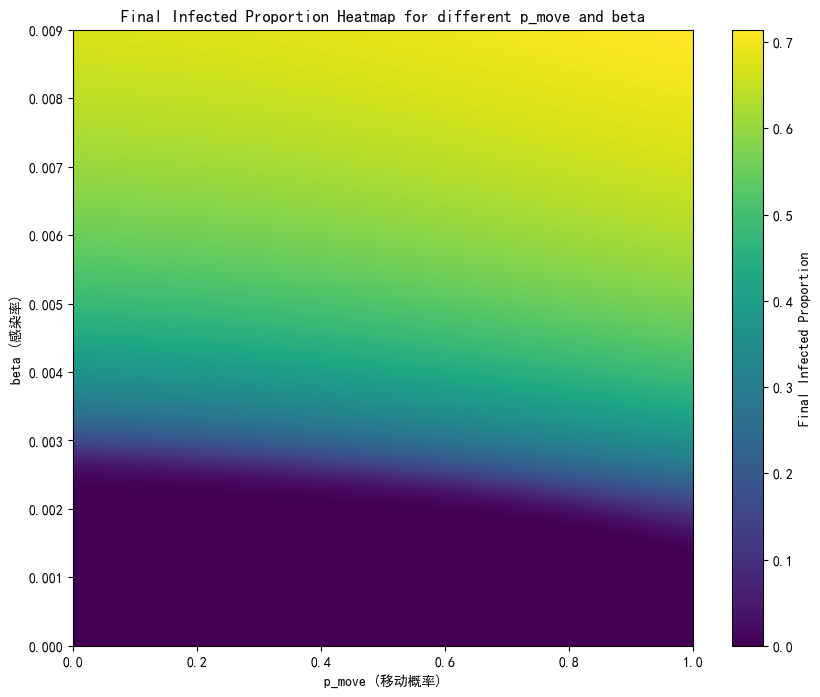

In [185]:


results_matrix = pd.read_csv('simulation_results_0927.csv', index_col=0)
# 绘制热力图
plt.figure(figsize=(10, 8))
plt.imshow(results_matrix, cmap='viridis', aspect='auto', origin='lower', interpolation='gaussian',
           extent=[p_move_values[0], p_move_values[-1], beta_values[0], beta_values[-1]])
print(results_matrix.shape)
print(len(p_move_values), len(beta_values))
# plt.imshow(results_matrix, cmap='viridis', aspect='auto', origin='lower', interpolation='gaussian')
# plt.xticks([0, len(p_move_values) // 2, len(p_move_values) ], [r'$0$', r'$0.5$', r'$1$'])
# plt.yticks([0, len(beta_values) // 2, len(beta_values) ], [r'$0$', r'$0.5$', r'$1$'])

plt.colorbar(label='Final Infected Proportion')
plt.xlabel('p_move (移动概率)')
plt.ylabel('beta (感染率)')
plt.title('Final Infected Proportion Heatmap for different p_move and beta')
plt.show()


In [186]:
beta_values = np.arange(0.0, 0.0092, 0.0002)
print(len(beta_values))
print(beta_values)

p_move_values = np.arange(0.0, 1.025, 0.025)
print(len(p_move_values))
p_move_values


46
[0.     0.0002 0.0004 0.0006 0.0008 0.001  0.0012 0.0014 0.0016 0.0018
 0.002  0.0022 0.0024 0.0026 0.0028 0.003  0.0032 0.0034 0.0036 0.0038
 0.004  0.0042 0.0044 0.0046 0.0048 0.005  0.0052 0.0054 0.0056 0.0058
 0.006  0.0062 0.0064 0.0066 0.0068 0.007  0.0072 0.0074 0.0076 0.0078
 0.008  0.0082 0.0084 0.0086 0.0088 0.009 ]
41


array([0.   , 0.025, 0.05 , 0.075, 0.1  , 0.125, 0.15 , 0.175, 0.2  ,
       0.225, 0.25 , 0.275, 0.3  , 0.325, 0.35 , 0.375, 0.4  , 0.425,
       0.45 , 0.475, 0.5  , 0.525, 0.55 , 0.575, 0.6  , 0.625, 0.65 ,
       0.675, 0.7  , 0.725, 0.75 , 0.775, 0.8  , 0.825, 0.85 , 0.875,
       0.9  , 0.925, 0.95 , 0.975, 1.   ])